# Week 6: Applied Computer Vision in Your Own Domain

### Part 0: The Configuration Cell

In [7]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [8]:
for root, dirs, files in os.walk('/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database'):
    n_img = sum(f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')) for f in files)
    if n_img:
        print(root, '| images:', n_img)

/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/crazing | images: 240
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/inclusion | images: 240
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/patches | images: 240
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/pitted_surface | images: 240
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/rolled-in_scale | images: 240
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/train/images/scratches | images: 240
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/validation/images/crazing | images: 60
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/validation/images/inclusion | images: 60
/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET/validation/image

In [9]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database/NEU-DET'
TRAIN_DIR = f'{DATA_ROOT}/train/images'        # folder with one subfolder per class
TEST_DIR  = f'{DATA_ROOT}/validation/images'   # held-out set, used once at the end
GRAYSCALE = True                               # steel surface scans are grayscale
IMG_SIZE  = 224
BACKBONE  = 'resnet18'                         # or 'resnet50', 'efficientnet_b0'
GROUP_PATTERN = None                           # no subject id in the file names (see below)
POSITIVE = None                                # 6 classes, so no binary threshold
TARGET_RECALL = None                           # unused for multi-class
# ======================================================================

# Part 1: Index and Audit Your Dataset

## Task 1.1: One row per image

In [10]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
crazing            240
inclusion          240
patches            240
pitted_surface     240
rolled-in_scale    240
scratches          240
Imbalance ratio (max / min): 1.0
Images per group: 1.00


## Task 1.2: What do the images look like?

         w      h
min  200.0  200.0
50%  200.0  200.0
max  200.0  200.0
Colour modes: {'RGB': 300}


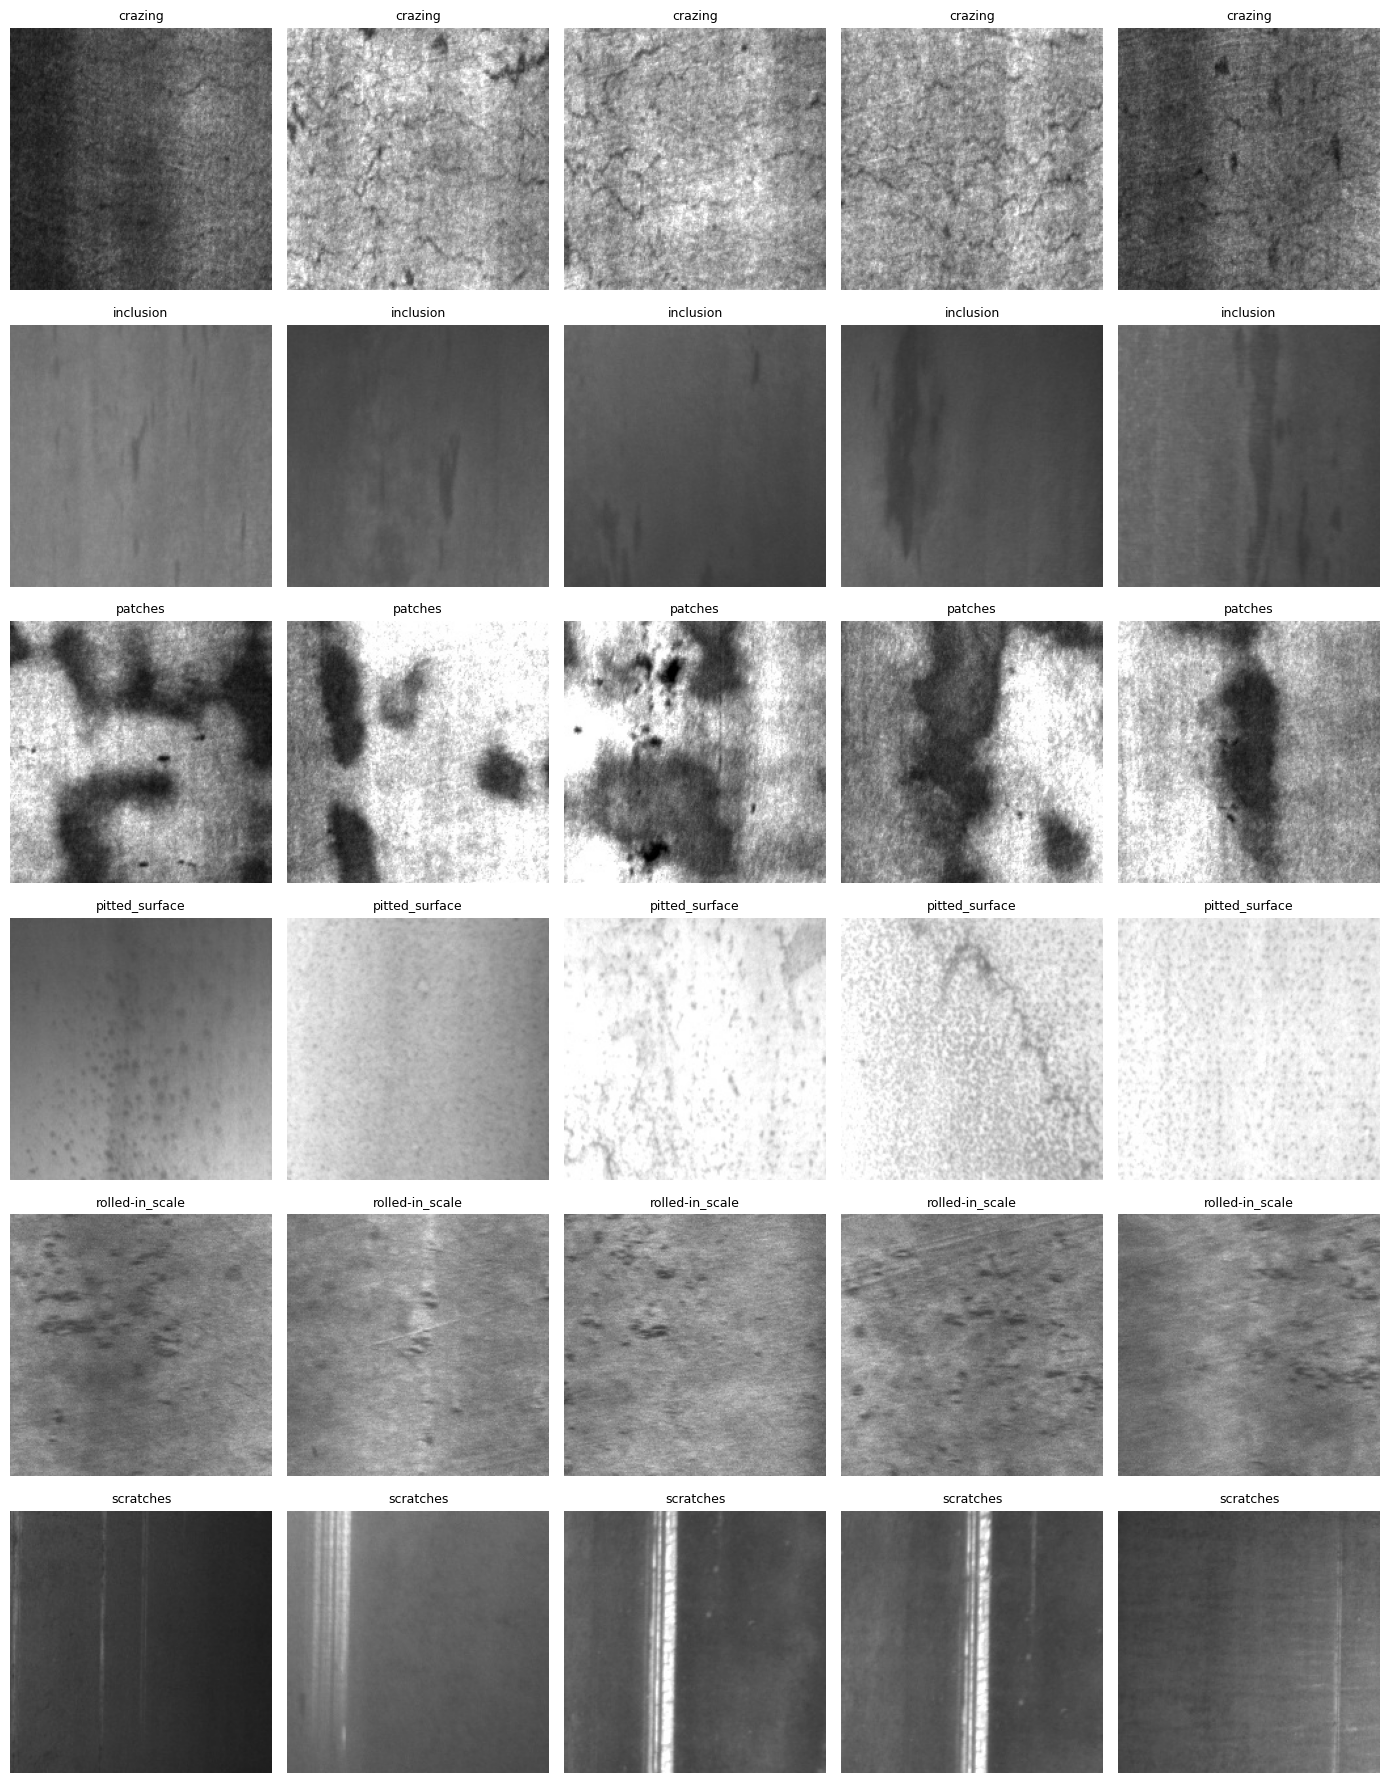

In [11]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

# Part 1: Write it

**What we did:** We built a table with one row per image (path, class, file name, group) and audited the dataset: class counts, imbalance ratio, image size and colour mode, and a grid of five sample images from each class.

**Class counts and imbalance ratio:** The training folder has 6 defect classes with 240 images each: crazing, inclusion, patches, pitted_surface, rolled-in_scale and scratches (1,440 images in total). The imbalance ratio (max / min) is 1.0, so the classes are perfectly balanced.

**Colour and size:** In a random sample of 300 images, all are 200 x 200 pixels and all are stored in RGB mode. They look grayscale, so the pipeline converts them to grayscale and then back to 3 channels for the pretrained network.

**First shortcut suspect: overall brightness.** In the sample grid, patches and pitted_surface images are bright, almost white, while inclusion and scratches images are dark grey. Brightness is not the defect itself, so a model could partly rely on it. This is only a suspect: crazing images range from dark to bright, and several images have a lighting gradient from left to right.

# Part 2: Leakage Audit

## Task 2.1: Exact and near-duplicates

In [12]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10                # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 2
Test images with a near-duplicate in train: 0 of 360
Closest distances: [0.108 0.115 0.115 0.126 0.126]


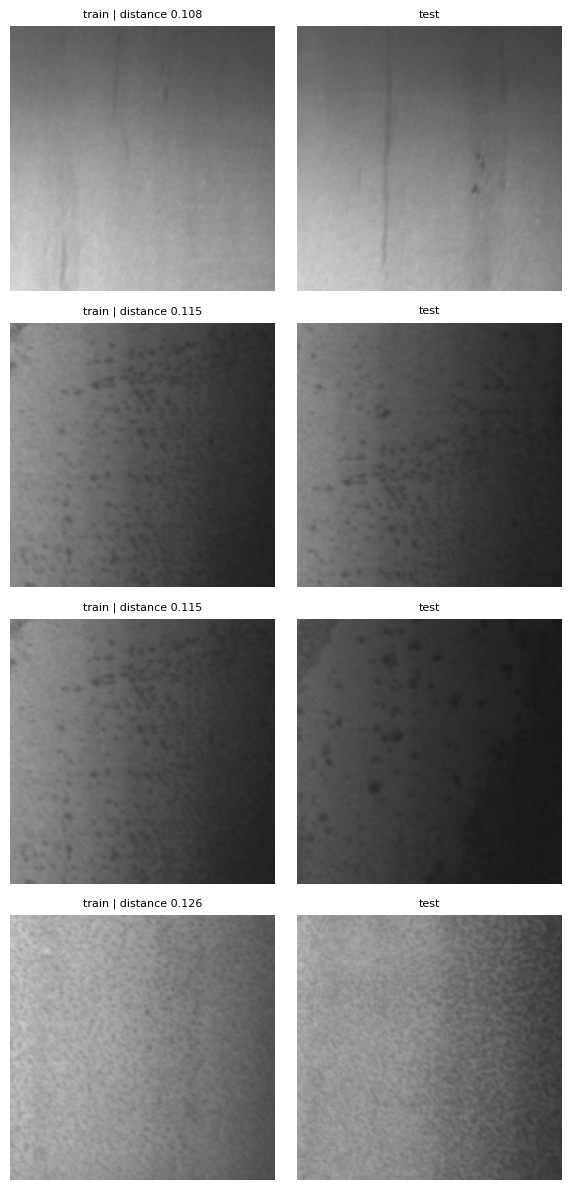

In [13]:
if TEST_DIR:
    train_paths = all_df[all_df.split == 'train']['path'].tolist()
    test_paths = all_df[all_df.split == 'test']['path'].tolist()
    order = np.argsort(d_min)[:4]
    fig, axes = plt.subplots(len(order), 2, figsize=(6, 3 * len(order)))
    axes = np.atleast_2d(axes)
    for r, ti in enumerate(order):
        tri = int(np.abs(tr - te[ti]).mean(axis=1).argmin())
        axes[r, 0].imshow(Image.open(train_paths[tri]).convert('RGB'))
        axes[r, 0].set_title(f'train | distance {d_min[ti]:.3f}', fontsize=8)
        axes[r, 1].imshow(Image.open(test_paths[ti]).convert('RGB'))
        axes[r, 1].set_title('test', fontsize=8)
        for a in axes[r]:
            a.axis('off')
    plt.tight_layout()
    plt.show()

In [14]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

train 1200 | val 240 | test 360
Groups shared by train and val: 0
label
inclusion          41
pitted_surface     41
crazing            40
rolled-in_scale    40
patches            39
scratches          39


# Part 2: Write it

**What we did:** We looked for exact duplicates (identical files, using an MD5 hash) and near-duplicates (resized or recompressed copies, using a standardized 32x32 thumbnail) between train and test. We viewed the closest pairs before changing anything. Then we split the training data into train and validation with a grouped split and checked that no group appears on both sides.

**Duplicates:** There are 2 exact duplicate files, meaning one identical pair: [write which splits they are in, from the cell above]. No test image is a near-duplicate of a train image (0 of 360 below the 0.10 threshold). The closest distances were 0.108, 0.115, 0.115, 0.126 and 0.126, only just above the threshold. I displayed the 4 closest pairs side by side: they are not the same image. They show similar steel texture and lighting, but the defects sit in different places. So I removed no near-duplicates. [Add what you did about the exact pair.]

**Images per group:** 1.00. The file names have no patient or part ID, so I set GROUP_PATTERN = None and every image is its own group. The split gave train 1,200, validation 240 and test 360, with 0 groups shared between train and validation. Validation has 41, 41, 40, 40, 39 and 39 images per class, so it is balanced.

**Random vs group split:** If images of the same subject were split randomly, near-identical images would land in both train and test and the model would score well by recognising images it had already seen, which would inflate the test score. Here every image is its own group, so a random split would behave the same as the grouped one, and the near-duplicate check is what protects the test score.

# Part 3: Transforms and Imbalance 

## Task 3.1: Datasets and transforms

In [15]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

In [16]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'crazing': np.float64(1.0), 'inclusion': np.float64(1.005), 'patches': np.float64(0.995), 'pitted_surface': np.float64(1.005), 'rolled-in_scale': np.float64(1.0), 'scratches': np.float64(0.995)}


# Part 3: Write it

**What we did:** We defined the image transforms (augmentation for training, plain resizing for validation and test), wrapped the data in datasets and loaders, and computed class weights for the loss with N / (K x n_c).

**Class weights:** crazing 1.0, inclusion 1.005, patches 0.995, pitted_surface 1.005, rolled-in_scale 1.0, scratches 0.995. Example for inclusion: N = 1200 training images, K = 6 classes and n_c = 199 images, so the weight is 1200 / (6 x 199) = 1200 / 1194 = 1.005. Patches has 201 images: 1200 / (6 x 201) = 0.995. Every weight is about 1.0 because the classes are balanced, so weighted loss behaves almost like ordinary loss here and imbalance is not a problem in this dataset. I used the weighted loss and did not try the balanced sampler.

**Augmentations:** I kept RandomResizedCrop (scale 0.8 to 1.0) and RandomRotation (10 degrees), because small shifts and tilts in framing are realistic for images of steel strips. I kept ColorJitter (brightness and contrast 0.15) because lighting varies between images, and it may also reduce reliance on brightness, my first shortcut suspect. I left out flips and strong distortions to keep the defects looking realistic.

# Part 4: Build and Train

## Task 4.1: Backbone with a new head

In [17]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 258MB/s]


resnet18 trainable: 3078


## Task 4.2: Two-phase training, selected by macro-F1

In [18]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.744 (6s)
epoch 2: val macro-F1 0.975 (5s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.987 (5s)
epoch 2: val macro-F1 0.996 (5s)
epoch 3: val macro-F1 1.000 (5s)


1.0

# Part 4: Write it

**What we did:** We loaded a pretrained ResNet18 and replaced its last layer with a 6-class head (3,078 trainable parameters). Phase 1 trained only the head for 2 epochs. Phase 2 also fine-tuned the last block for 3 epochs. After every epoch we computed validation macro-F1 and kept the best epoch, so selection used macro-F1 and not accuracy.

**Validation macro-F1:** Phase 1 reached 0.744 after epoch 1 and 0.975 after epoch 2, so its best was 0.975. Phase 2 reached 0.987, then 0.996, then 1.000, so its best was 1.000.

**Did fine-tuning help?** Yes. It raised validation macro-F1 from 0.975 to 1.000. A perfect validation score on 240 images is also a sign that the task is fairly easy, and the best epoch was picked on this same validation set, so it is slightly optimistic.

**Time per epoch:** About 5 seconds on the GPU. Validation macro-F1 had already reached 1.000, so with more time I would add only a few epochs, mainly to check that the score stays stable, and spend the rest on a harder or larger validation set.

# Part 5: Test Once, and Set the Threshold 

## Task 5.1: Test-set report

                 precision    recall  f1-score   support

        crazing      1.000     1.000     1.000        60
      inclusion      1.000     0.983     0.992        60
        patches      1.000     1.000     1.000        60
 pitted_surface      1.000     1.000     1.000        60
rolled-in_scale      1.000     1.000     1.000        60
      scratches      0.984     1.000     0.992        60

       accuracy                          0.997       360
      macro avg      0.997     0.997     0.997       360
   weighted avg      0.997     0.997     0.997       360

Macro-F1: 0.997


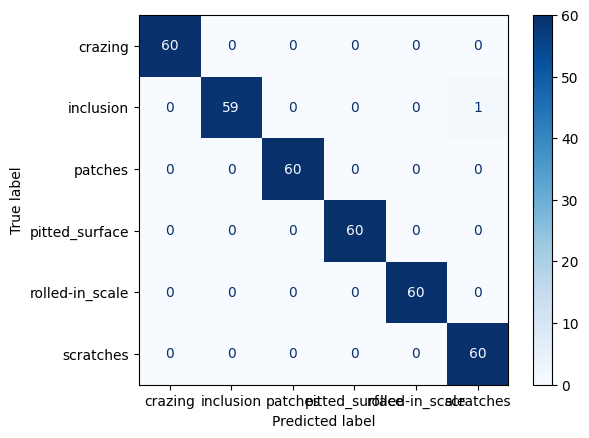

In [19]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

## Task 5.2: Threshold for a target recall (binary tasks)

In [20]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]   # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')

# Part 5: Write it

**What we did:** We evaluated the trained model on the held-out test set (the dataset's validation folder, 60 images per class, 360 in total) with a per-class report and a confusion matrix. The threshold-for-recall step applies to two-class problems only. This task has six classes, so we analysed per-class recall instead.

**Macro-F1:** 0.997 (accuracy also 0.997).

**Weakest class:** Inclusion has the lowest recall, 0.983: 59 of 60 were correct and 1 was predicted as scratches. Scratches has the lowest precision, 0.984, because of that same mistake. That is the only error out of 360 images. Both defects can appear as elongated streaks, so the confusion is plausible. All other classes scored 1.000 on precision and recall.

**Binary metrics:** Not applicable, because there are 6 classes, so no threshold, sensitivity, specificity or PPV was computed. A single error is only 0.3% of the test set, so this score should not be read as a guarantee on a real production line.

# Part 6: Grad-CAM Shortcut Check

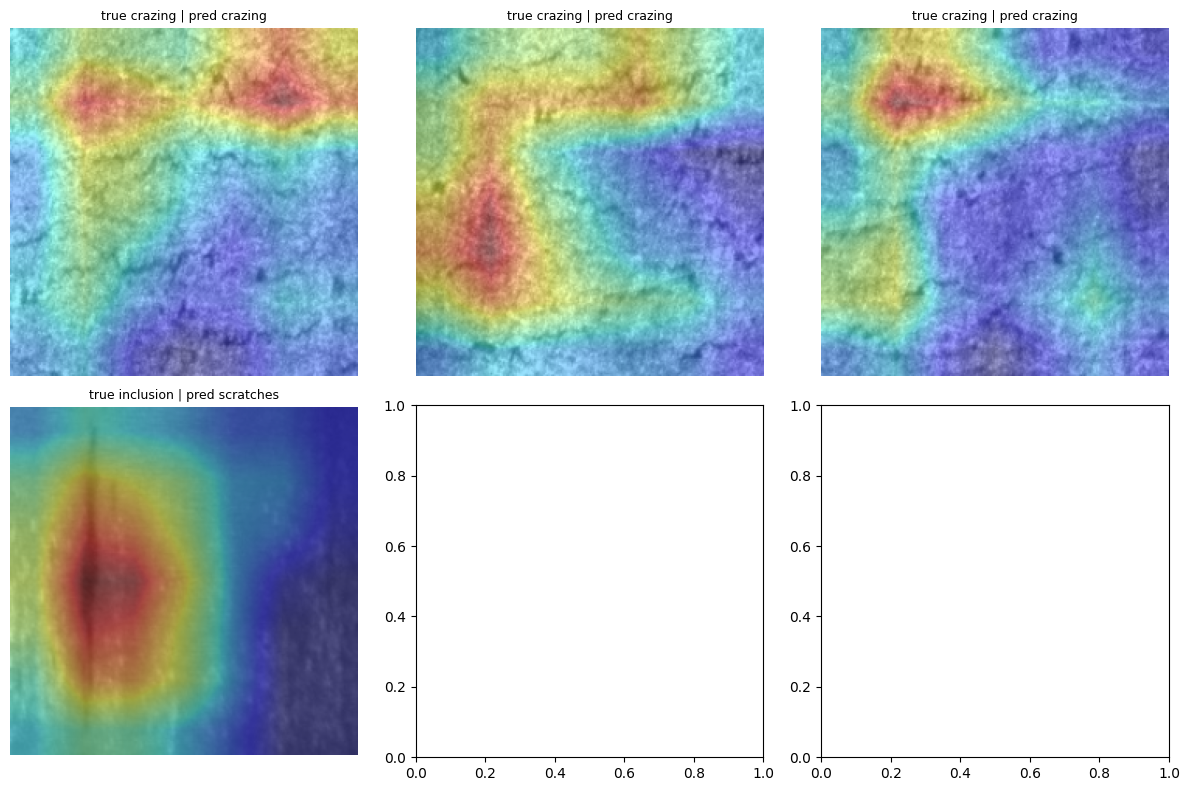

In [21]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Part 6: Write it

**What we did:** We used Grad-CAM to highlight which image regions drove each prediction, for correct and wrong test predictions, to check whether the model looks at real defect evidence or a shortcut.

1. True crazing, predicted crazing: two hot spots along the top, on crack junctions in the surface texture. Legitimate evidence.
2. True crazing, predicted crazing: a vertical band on the left and a horizontal band across the top, following the crack network. Legitimate.
3. True crazing, predicted crazing: one hot spot at the upper left, on a crack junction. Legitimate, though it is less spread out.
4. True inclusion, predicted scratches (the one error): attention is concentrated on a dark vertical streak at the left of the image. The model looked at the real defect, but its long, thin vertical shape resembles a scratch, which probably explains the mistake.
5. and 6. Not shown: the model made only one mistake on the test set, so there were no more wrong examples to display.

**Verdict: no shortcut found, with limited confidence.** In all four heatmaps the attention sits on the defect and the surface texture, not on borders, corners or the brightness of the whole image, and these images contain no text or labels. The sample is small, and all three correct examples are the same class, because the code takes the first three correct test images in sorted order.

**Follow-up experiment:** For one correctly classified image per class, mask or crop out the highlighted region and re-score. A large drop in confidence would show the model depends on that region. I would also test brightness directly: darken or brighten the images and see whether predictions change.

# Part 7: Save and Document

In [22]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')


Saved week6_model.pt


# Conclusion

**What I did:** I built a complete computer vision pipeline that classifies six types of surface defect on strip steel (crazing, inclusion, patches, pitted_surface, rolled-in_scale and scratches), using a pretrained ResNet18 on the NEU Surface Defect Database. The pipeline audited the data, checked for leakage, handled class weights, trained in two phases with the best epoch chosen by macro-F1, tested once, and checked the model with Grad-CAM.

**What I found about the data:** The 1,440 training images are perfectly balanced (240 per class, imbalance ratio 1.0), so the class weights came out between 0.995 and 1.005 and imbalance was not a problem. There was no test image with a near-duplicate in train (0 of 360), and I found one pair of exact duplicate files. The file names contain no subject ID, so every image is its own group and the grouped split shared 0 groups between train and validation. My first shortcut suspect was overall image brightness, because patches and pitted_surface images are much brighter than inclusion and scratches images.

**What I found about the model:** Fine-tuning the last block raised validation macro-F1 from 0.975 to 1.000, at about 5 seconds per epoch. On the 360 test images, used once, the model reached **macro-F1 0.997 and accuracy 0.997**. It made a single error: one inclusion image predicted as scratches. Both defects can appear as long, thin streaks, so this confusion is understandable. Grad-CAM showed the model looking at the defect and the surface texture, for example crack junctions on crazing images and a dark vertical streak on the misclassified inclusion image. I found no sign of a shortcut such as borders, corners or text, but I inspected only a few heatmaps, so my verdict is "no shortcut found, with limited confidence".

**What surprised me:** How easy this dataset is. A near-perfect score came after only five epochs, and validation macro-F1 reached 1.000. A score that high should make me more careful, not more confident, because the test set is small (one error is 0.3%), the best epoch was chosen on a validation set from the same data, and all images come from one controlled setting. The checks that matter here were the leakage audit and Grad-CAM, because they test whether the score is trustworthy, and a single accuracy number cannot show that.

**Limitations:** One dataset, one camera and lighting setup, 200 x 200 images, six defect types, and no defect-free class. The model has not been tested on other steel grades, mills, cameras or lighting. It should not be used for automatic accept/reject decisions without further validation and a human reviewing its predictions.

**What I would do next:**
1. Test brightness directly: darken and brighten the test images and check whether predictions change.
2. Mask the Grad-CAM region on one correct image per class and re-score, to confirm the model depends on the defect.
3. Evaluate on images from a different line or camera, and add a "no defect" class.
4. Try the balanced sampler and a second backbone (efficientnet_b0) and compare macro-F1.
5. Run several seeds and report the spread, instead of one run.